# P2 검증 노트북: 효율맵과 손실 분포

`engine/losses.py`의 효율맵을 그림으로 확인한다. **철손·기계손 계수는 테스트용 합성 값이다**(실제 강판·베어링 데이터가 아님). 그래서 이 그림의 효율 수치는 모양을 보기 위한 것이고, 실제 모터와 비교하는 것은 P3(ORNL 프리우스 2004)에서 한다.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from engine.model import ConstantParamModel
from engine.operating import Limits, max_torque_curve
from engine.losses import IronParams, MechParams, efficiency_map

P, RS = 4, 0.03
model = ConstantParamModel(p=P, Rs=RS, Ld=0.15e-3, Lq=0.45e-3, psi_m=0.075)
limits = Limits(Imax=250.0, Vdc=350.0)
iron = IronParams(k_h=0.02, k_e=5e-5, beta=2.0, m_tooth=3.0, m_yoke=6.0, c_tooth=20.0, c_yoke=10.0)  # 합성값
mech = MechParams(a=0.01, b=2e-8)                                                                     # 합성값
rpm = lambda w: w * 30 / np.pi

## 1. 효율맵
토크 40점 × 속도 60점(2400점)을 한 번에 계산한다. 동작점은 각 (T, ω)에서 전류가 최소인 (id, iq)이다. 흰 영역은 전류·전압 제한으로 낼 수 없는 영역이고, 검은 선이 `max_torque_curve`의 경계다.

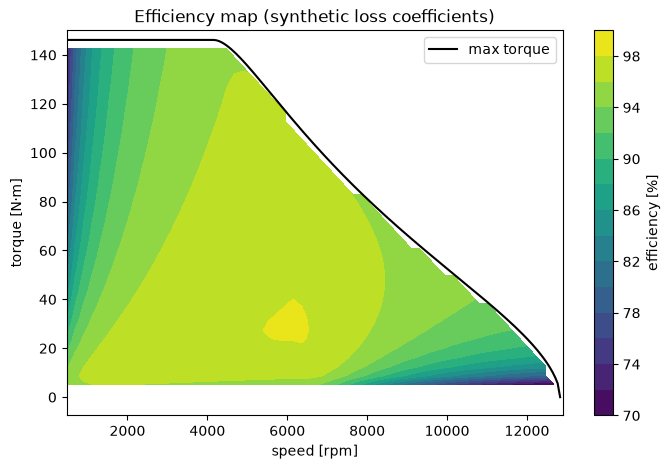

계산 시간 0.74 s, 점 수 2400, 실행 가능 1492
최고 효율 98.1 % at 31 N·m, 6158 rpm


In [2]:
T = np.linspace(5.0, 150.0, 40)
w = np.linspace(50.0, 1350.0, 60)
t0 = time.perf_counter()
em = efficiency_map(model, limits, T, w, iron, mech)
dt = time.perf_counter() - t0
tab = max_torque_curve(model, limits, np.linspace(50.0, 1350.0, 200))

fig, ax = plt.subplots(figsize=(8, 5))
cs = ax.contourf(rpm(w), T, em.eta * 100, levels=np.arange(70, 100.1, 2), cmap="viridis")
fig.colorbar(cs, label="efficiency [%]")
ax.plot(rpm(tab.speed[tab.feasible]), tab.T_max[tab.feasible], "k", lw=1.5, label="max torque")
ax.set(xlabel="speed [rpm]", ylabel="torque [N·m]", title="Efficiency map (synthetic loss coefficients)")
ax.legend(); plt.show()
print(f"계산 시간 {dt:.2f} s, 점 수 {em.feasible.size}, 실행 가능 {em.feasible.sum()}")
i, j = np.unravel_index(np.nanargmax(em.eta), em.eta.shape)
print(f"최고 효율 {em.eta[i, j]*100:.1f} % at {T[i]:.0f} N·m, {rpm(w[j]):.0f} rpm")

## 2. 손실 분포
토크 60 N·m에서 속도에 따라 손실 성분이 어떻게 달라지는지 본다. 합성 계수에서는 전 구간에서 동손이 가장 크다. 기저속도(약 4000 rpm) 위 약계자 영역에서는 `id`가 음으로 커져 같은 토크에 더 큰 전류가 들어가므로 동손이 급격히 늘고, 철손은 속도에 따라 서서히 는다. 성분 비율은 합성 계수에 따라 달라지므로 실제 비율은 P3 이후에 본다.

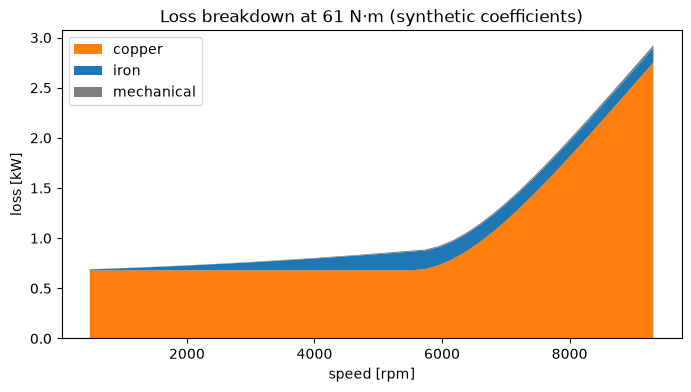

손실 수지 P_in − P_out = P_cu + P_fe + P_mech 최대 오차 [W]: 1.8189894035458565e-11


In [3]:
i60 = np.argmin(np.abs(T - 60.0))
f = em.feasible[i60]
fig, ax = plt.subplots(figsize=(8, 4))
x = rpm(w[f])
ax.stackplot(x, em.P_cu[i60, f] / 1e3, em.P_fe[i60, f] / 1e3, em.P_mech[i60, f] / 1e3,
             labels=["copper", "iron", "mechanical"], colors=["tab:orange", "tab:blue", "tab:gray"])
ax.set(xlabel="speed [rpm]", ylabel="loss [kW]", title=f"Loss breakdown at {T[i60]:.0f} N·m (synthetic coefficients)")
ax.legend(loc="upper left"); plt.show()
loss = em.P_in - em.P_out
print("손실 수지 P_in − P_out = P_cu + P_fe + P_mech 최대 오차 [W]:",
      np.nanmax(np.abs(loss - (em.P_cu + em.P_fe + em.P_mech))))